# 01 — Exploração dos dados

Objetivo: perceber o dataset CirCor antes de desenhar os modelos.

1. Pacientes e classes
2. Gravações por paciente e locais de auscultação
3. Duração das gravações
4. Onde o sopro é audível (`Murmur locations`)
5. Segmentação do ciclo cardíaco (`.tsv`)
6. Sinais, espetro e mel-espectrogramas por classe
7. Divisão treino/validação/teste
8. Conclusões

In [1]:
import sys; sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
from scipy.signal import welch

from src.data import load_patients, load_recordings, load_split, load_audio, load_segmentation, SAMPLE_RATE
from src.metrics import weighted_accuracy, CLASSES

sns.set_theme(style="whitegrid")
COLORS = {"Present": "tab:red", "Unknown": "tab:orange", "Absent": "tab:blue"}

patients = load_patients()
recordings = load_recordings()
print(f"{len(patients)} pacientes, {len(recordings)} gravações")

942 pacientes, 3163 gravações


## 1. Pacientes e classes

O rótulo `Murmur` é do **paciente**. As classes estão muito desequilibradas.

,pacientes,%
murmur,,
Present,179,19.0
Unknown,68,7.2
Absent,695,73.8


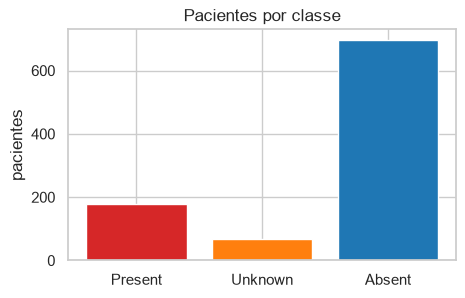

In [2]:
counts = patients["murmur"].value_counts().reindex(CLASSES)
display(pd.DataFrame({"pacientes": counts, "%": (100 * counts / counts.sum()).round(1)}))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color=[COLORS[c] for c in counts.index])
ax.set_ylabel("pacientes"); ax.set_title("Pacientes por classe")
plt.show()

**Classificadores triviais.** A weighted accuracy dá peso 5 a *Present*, 3 a *Unknown* e 1 a *Absent*.
Prever sempre a classe maioritária tem accuracy alta mas WA baixa. Estes valores servem de referência mínima.

In [3]:
y = patients["murmur"].tolist()
baselines = {c: {"accuracy": np.mean([t == c for t in y]), "weighted accuracy": weighted_accuracy(y, [c] * len(y))}
             for c in CLASSES}
pd.DataFrame(baselines).T.rename_axis("prever sempre").round(3)

,accuracy,weighted accuracy
prever sempre,,
Present,0.190,0.499
Unknown,0.072,0.114
Absent,0.738,0.387


**Outras variáveis do paciente.** Não vamos usá-las como entrada, mas ajudam a perceber os dados.

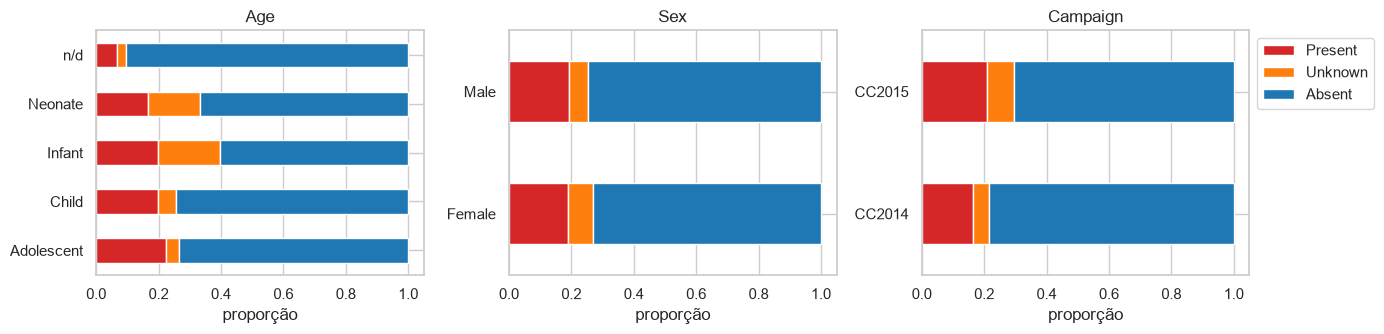

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["Age", "Sex", "Campaign"]):
    pd.crosstab(patients[col].fillna("n/d"), patients["murmur"], normalize="index")[CLASSES] \
        .plot.barh(stacked=True, ax=ax, color=[COLORS[c] for c in CLASSES], legend=False)
    ax.set_title(col); ax.set_xlabel("proporção"); ax.set_ylabel("")
axes[-1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

## 2. Gravações por paciente e locais de auscultação

In [5]:
per_patient = recordings.groupby("patient_id").size()
print("gravações por paciente:"); display(per_patient.value_counts().sort_index().rename("pacientes").to_frame().T)

display(pd.crosstab(recordings["location"], recordings["murmur"])[CLASSES])

repeated = recordings.groupby(["patient_id", "location"]).size()
print(f"{(repeated > 1).sum()} pares paciente/local com mais de uma gravação (ficheiros _1, _2, ...)")

gravações por paciente:


,1,2,3,4,5,6
pacientes,62,156,123,588,10,3


murmur,Present,Unknown,Absent
location,,,
AV,152,45,603
MV,172,52,637
PV,147,33,586
Phc,2,0,2
TV,143,26,563


21 pares paciente/local com mais de uma gravação (ficheiros _1, _2, ...)


**Legenda dos locais de auscultação.** Cada local é um ponto do peito onde se ouve melhor uma das quatro válvulas do coração.

| Sigla | Válvula / foco | Onde fica no peito |
|---|---|---|
| **AV** | Aórtica (*Aortic Valve*) | 2.º espaço intercostal, à direita do esterno |
| **PV** | Pulmonar (*Pulmonary Valve*) | 2.º espaço intercostal, à esquerda do esterno |
| **TV** | Tricúspide (*Tricuspid Valve*) | 4.º–5.º espaço intercostal, junto ao bordo esquerdo do esterno |
| **MV** | Mitral (*Mitral Valve*) | 5.º espaço intercostal esquerdo, na linha média da clavícula (ponta do coração) |
| **Phc** | Outro local (qualquer ponto fora dos quatro focos) | Não especificado; só 4 gravações no dataset |

## 3. Duração das gravações

,count,mean,std,min,25%,50%,75%,max
murmur,,,,,,,,
Present,616.0,22.3,7.9,6.4,18.2,21.0,28.6,64.5
Unknown,156.0,22.4,7.0,7.6,19.2,21.1,27.2,43.9
Absent,2391.0,23.1,7.1,5.2,19.1,21.7,29.6,58.8


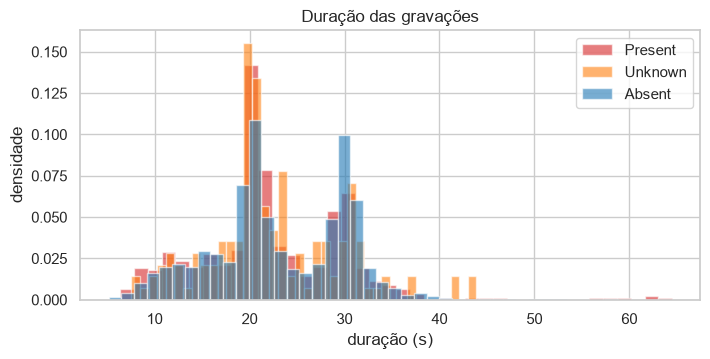

gravações com menos de  3 s: 0.0%
gravações com menos de  4 s: 0.0%
gravações com menos de  5 s: 0.0%
gravações com menos de  8 s: 1.0%
gravações com menos de 10 s: 3.6%


In [6]:
recordings["duration"] = [len(load_audio(p)) / SAMPLE_RATE for p in recordings["wav"]]
display(recordings.groupby("murmur")["duration"].describe().reindex(CLASSES).round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
for c in CLASSES:
    ax.hist(recordings.loc[recordings["murmur"] == c, "duration"], bins=40, alpha=0.6, label=c, color=COLORS[c], density=True)
ax.set_xlabel("duração (s)"); ax.set_ylabel("densidade"); ax.legend(); ax.set_title("Duração das gravações")
plt.show()

for s in [3, 4, 5, 8, 10]:
    print(f"gravações com menos de {s:>2} s: {(recordings['duration'] < s).mean():.1%}")

## 4. Onde o sopro é audível

O rótulo `Murmur` é do **paciente**, não de cada gravação. O médico ouviu o coração em vários pontos do peito (AV, PV, TV, MV):
se ouviu um sopro em **pelo menos um** deles, o paciente inteiro fica *Present*. Além disso, anotou **em que pontos** o ouviu,
no campo `Murmur locations` (só existe para pacientes *Present*). Em `load_recordings()` isto deu a coluna `murmur_audible`.

Um sopro nasce num sítio concreto (normalmente uma válvula com problema) e é mais forte perto dele; longe dali pode ser tão
fraco que não se ouve. Por isso, um paciente *Present* pode ter gravações que soam como um coração normal.

**Exemplo: paciente 13918.** É *Present*, tem gravações em AV, PV, TV e MV, e `Murmur locations = TV`:

| Gravação | `murmur` (herdado do paciente) | `murmur_audible` | O que há no áudio |
|---|---|---|---|
| 13918_AV | Present | False | sem sopro audível |
| 13918_PV | Present | False | sem sopro audível |
| 13918_TV | Present | **True** | **sopro** |
| 13918_MV | Present | False | sem sopro audível |

Três das quatro gravações dizem "*Present*", mas não têm sopro audível.

In [7]:
present = recordings[recordings["murmur"] == "Present"]
print(f"gravações de pacientes Present: {len(present)}")
print(f"  com sopro audível nesse local: {present['murmur_audible'].sum()} ({present['murmur_audible'].mean():.1%})")
print(f"  sem sopro audível nesse local: {(~present['murmur_audible']).sum()} ({(~present['murmur_audible']).mean():.1%})")

pp = patients[patients["murmur"] == "Present"]
n_audible = pp["Murmur locations"].str.split("+").str.len()
n_recorded = pp["Recording locations:"].str.split("+").apply(lambda l: len(set(l)))
display(pd.crosstab(n_audible.rename("locais com sopro"), n_recorded.rename("locais gravados")))

gravações de pacientes Present: 616
  com sopro audível nesse local: 499 (81.0%)
  sem sopro audível nesse local: 117 (19.0%)


locais gravados,1,2,3,4,5
locais com sopro,,,,,
1,10,8,4,12,0
2,0,19,7,21,0
3,0,0,11,16,0
4,0,0,0,70,0
5,0,0,0,0,1


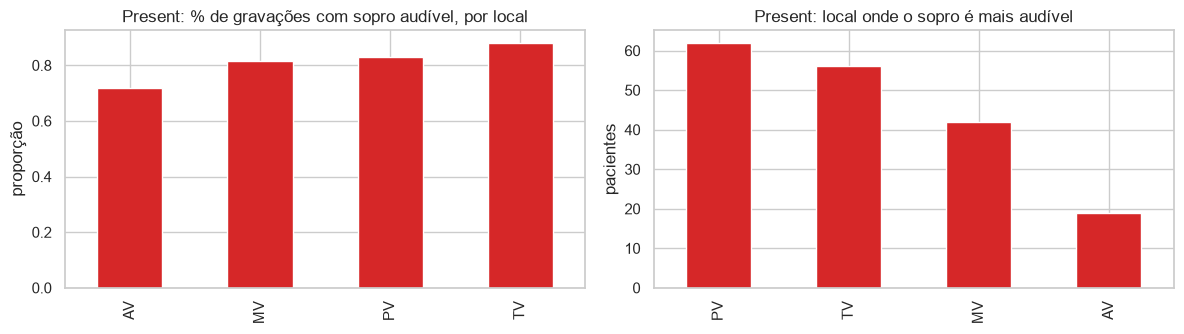

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
audible_by_loc = present.groupby("location")["murmur_audible"].mean().drop("Phc", errors="ignore")
audible_by_loc.plot.bar(ax=axes[0], color="tab:red")
axes[0].set_title("Present: % de gravações com sopro audível, por local"); axes[0].set_ylabel("proporção"); axes[0].set_xlabel("")
pp["Most audible location"].value_counts().plot.bar(ax=axes[1], color="tab:red")
axes[1].set_title("Present: local onde o sopro é mais audível"); axes[1].set_ylabel("pacientes"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

**O que isto implica**

1. **No treino, há rótulos enganosos.** Se cada gravação herdar o rótulo do paciente, cerca de 1 em cada 5 exemplos *Present*
   (117 de 616 no dataset, 77 no treino) não tem sopro nenhum. O modelo fica confuso ou aprende pistas erradas, sem relação
   com o sopro (idade, qualidade da gravação...), só para acertar esses exemplos.
2. **Na previsão não há problema, se a regra for a certa.** Para o paciente 13918, um bom modelo diria *Absent* em AV, PV e MV
   e *Present* em TV, e isso está **correto** gravação a gravação. Com a regra "o paciente é *Present* se **alguma** gravação for
   *Present*", o resultado final é *Present*, como faz o médico. A métrica (WA) é calculada **por paciente**, por isso o que
   conta é o resultado final.
3. **Opções para o treino** (testar as três e escolher pela WA na **validação**):

   | Opção | Como | Vantagem | Risco |
   |---|---|---|---|
   | (a) Rótulo do paciente | todas as gravações ficam *Present* | simples, segue o guião à letra | 19% de rótulos enganosos |
   | (b) Reetiquetar | gravações sem sopro audível passam a *Absent* | rótulos mais fiéis ao áudio | pode haver um sopro fraco que o médico não ouviu |
   | (c) Retirar | excluir essas gravações do treino | sem exemplos enganosos | perde 77 gravações do treino |

4. **Limite:** `murmur_audible` só pode servir para **corrigir os rótulos do treino**, nunca como entrada do modelo. Nos dados
   escondidos do bónus não há `Murmur locations`: o modelo tem de decidir só com o áudio. Como o guião diz para usar só o rótulo
   `Murmur`, é preciso **confirmar com o professor** se as opções (b) e (c) são permitidas.

## 5. Segmentação do ciclo cardíaco

Cada `.tsv` divide a gravação em S1, sístole, S2 e diástole. O estado 0 é um trecho **não anotado**
(normalmente ruído ou sinal difícil de segmentar).

In [9]:
STATES = {0: "não anotado", 1: "S1", 2: "sístole", 3: "S2", 4: "diástole"}

def segmentation_stats(path):
    seg = load_segmentation(path)
    seg["length"] = seg["end"] - seg["start"]
    total = seg["length"].sum()
    if total == 0:  # segmentação vazia ou corrompida
        return pd.Series({"frac_unannotated": np.nan, "heart_rate": np.nan})
    n_beats = (seg["state"] == 1).sum()
    annotated = seg.loc[seg["state"] > 0, "length"].sum()
    return pd.Series({"frac_unannotated": seg.loc[seg["state"] == 0, "length"].sum() / total,
                      "heart_rate": 60 * n_beats / annotated if annotated > 0 else np.nan})

seg_stats = recordings["tsv"].apply(segmentation_stats)
recordings[["frac_unannotated", "heart_rate"]] = seg_stats
print("gravações com segmentação inválida:", recordings.loc[seg_stats["frac_unannotated"].isna(), "tsv"].map(lambda p: p.name).tolist())
display(recordings.groupby("murmur")[["frac_unannotated", "heart_rate"]].describe().reindex(CLASSES).round(2).T)

gravações com segmentação inválida: ['50782_MV_1.tsv']


murmur                  Present  Unknown   Absent
frac_unannotated count   616.00   156.00  2390.00
                 mean      0.39     0.69     0.44
                 std       0.30     0.23     0.30
                 min       0.00     0.00     0.00
                 25%       0.08     0.59     0.15
                 50%       0.39     0.76     0.48
                 75%       0.68     0.85     0.71
                 max       0.96     0.96     0.94
heart_rate       count   616.00   156.00  2390.00
                 mean    107.07   120.48   105.46
                 std      21.22    31.17    20.96
                 min      44.58    59.68    49.15
                 25%      92.67    99.91    90.92
                 50%     106.28   119.26   104.02
                 75%     118.06   133.46   118.29
                 max     177.16   216.51   201.11

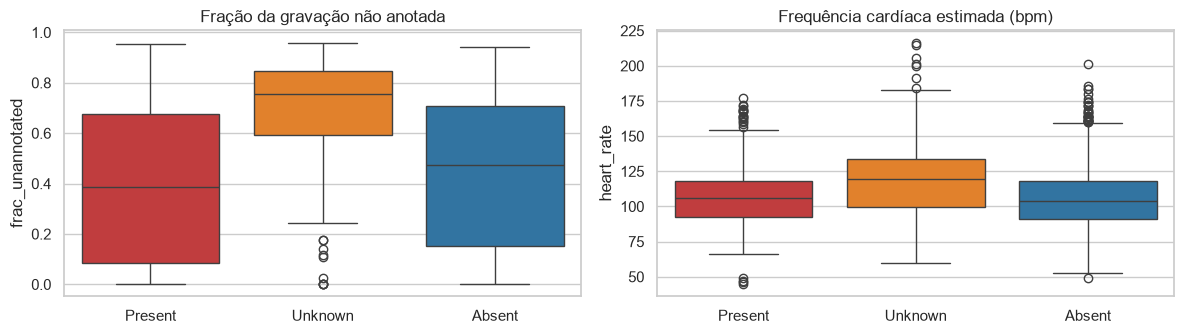

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(data=recordings, x="murmur", y="frac_unannotated", hue="murmur", order=CLASSES, palette=COLORS, legend=False, ax=axes[0])
axes[0].set_title("Fração da gravação não anotada"); axes[0].set_xlabel("")
sns.boxplot(data=recordings, x="murmur", y="heart_rate", hue="murmur", order=CLASSES, palette=COLORS, legend=False, ax=axes[1])
axes[1].set_title("Frequência cardíaca estimada (bpm)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

## 6. Sinais, espetro e mel-espectrogramas

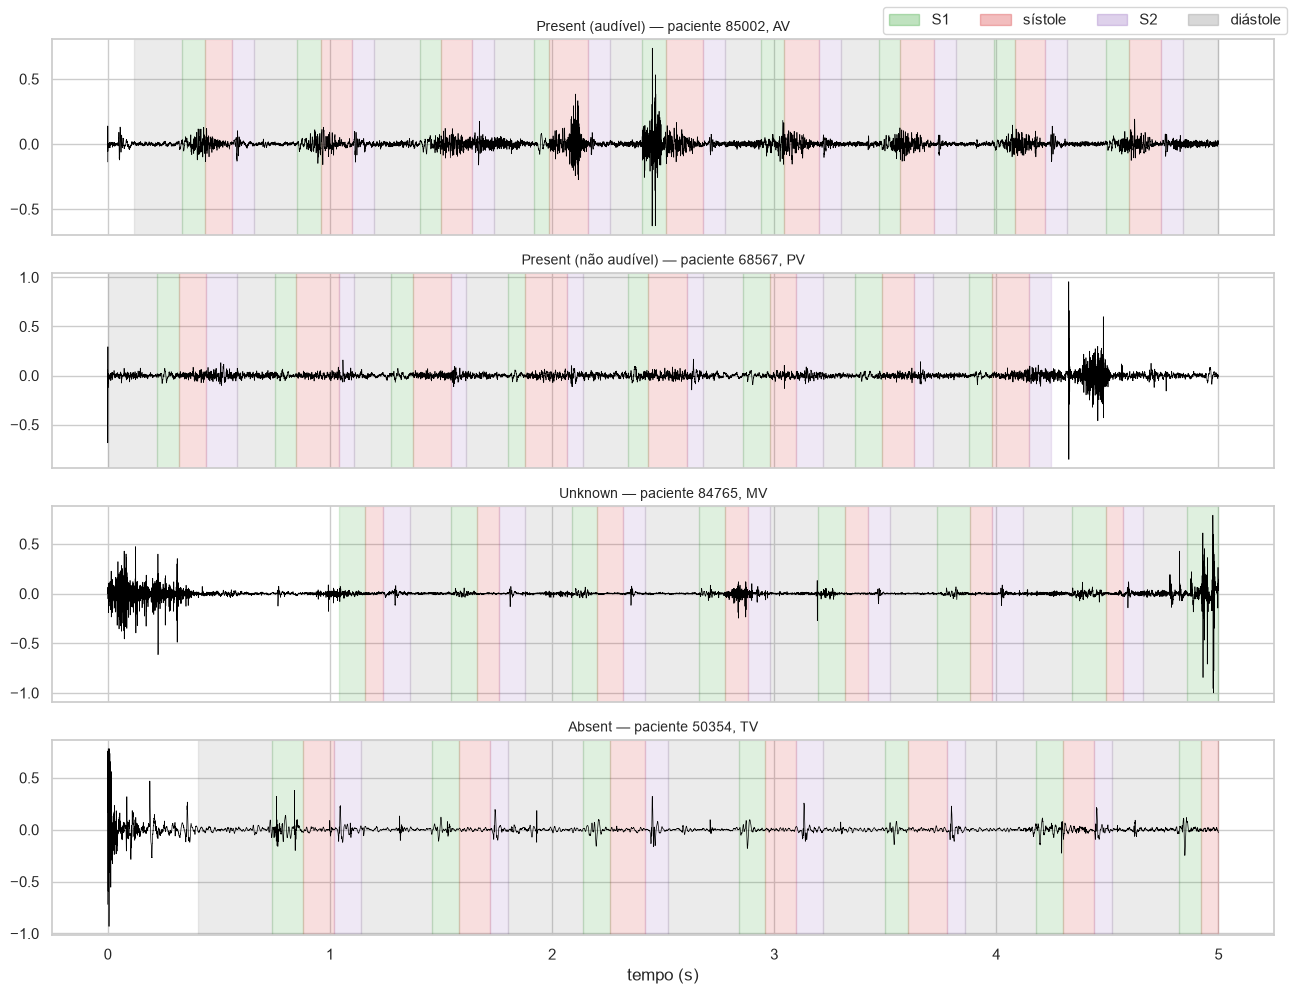

In [11]:
# Um exemplo por grupo: Present com sopro audível, Present sem sopro nesse local, Unknown e Absent.
# O exemplo é sorteado entre os 25% de gravações mais bem anotadas de cada grupo, para se ver o ciclo cardíaco.
rng = np.random.default_rng(0)
groups = {
    "Present (audível)": recordings[recordings["murmur_audible"]],
    "Present (não audível)": recordings[(recordings["murmur"] == "Present") & ~recordings["murmur_audible"]],
    "Unknown": recordings[recordings["murmur"] == "Unknown"],
    "Absent": recordings[recordings["murmur"] == "Absent"],
}
def pick_example(df):
    clean = df[df["frac_unannotated"] <= df["frac_unannotated"].quantile(0.25)]
    return clean.iloc[rng.integers(len(clean))]
examples = {name: pick_example(df) for name, df in groups.items()}
STATE_COLORS = {1: "tab:green", 2: "tab:red", 3: "tab:purple", 4: "tab:gray"}

fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
for ax, (name, rec) in zip(axes, examples.items()):
    x = load_audio(rec["wav"])[: 5 * SAMPLE_RATE]
    t = np.arange(len(x)) / SAMPLE_RATE
    ax.plot(t, x, lw=0.5, color="black")
    for _, s in load_segmentation(rec["tsv"]).iterrows():
        if s["state"] > 0 and s["start"] < 5:
            ax.axvspan(s["start"], min(s["end"], 5), color=STATE_COLORS[s["state"]], alpha=0.15)
    ax.set_title(f"{name} — paciente {rec['patient_id']}, {rec['location']}", fontsize=10)
axes[-1].set_xlabel("tempo (s)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.3) for c in STATE_COLORS.values()]
fig.legend(handles, [STATES[s] for s in STATE_COLORS], loc="upper right", ncol=4)
plt.tight_layout(); plt.show()

**Espetro médio.** Um sopro é turbulência no fluxo de sangue, que costuma acrescentar energia em frequências mais altas
do que os sons S1/S2. Comparamos o espetro de potência médio (Welch) de cada grupo.

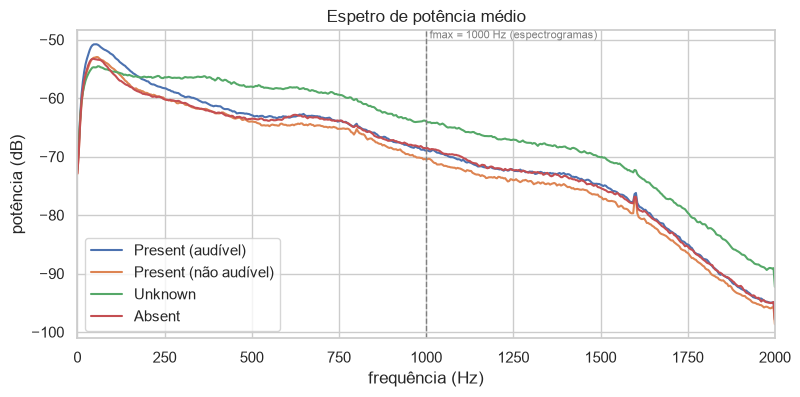

In [12]:
def mean_spectrum(paths, n=150):
    paths = rng.choice(paths, size=min(n, len(paths)), replace=False)
    spectra = []
    for p in paths:
        x = load_audio(p)
        f, pxx = welch(x / (np.abs(x).max() + 1e-9), fs=SAMPLE_RATE, nperseg=1024)
        spectra.append(10 * np.log10(pxx + 1e-12))
    return f, np.mean(spectra, axis=0)

fig, ax = plt.subplots(figsize=(9, 4))
for name, df in groups.items():
    f, s = mean_spectrum(df["wav"].to_numpy())
    ax.plot(f, s, label=name)
ax.axvline(1000, color="gray", ls="--", lw=1)
ax.text(1010, ax.get_ylim()[1], "fmax = 1000 Hz (espectrogramas)", va="top", fontsize=8, color="gray")
ax.set_xlim(0, SAMPLE_RATE / 2); ax.set_xlabel("frequência (Hz)"); ax.set_ylabel("potência (dB)")
ax.set_title("Espetro de potência médio"); ax.legend()
plt.show()

In [13]:
# Fração da energia de cada gravação por faixa de frequência: quanto se perde ao cortar os espectrogramas em 1000 Hz?
BANDS = {"< 200 Hz": (0, 200), "200–500 Hz": (200, 500), "500–1000 Hz": (500, 1000), "> 1000 Hz": (1000, SAMPLE_RATE / 2 + 1)}

def band_fractions(path):
    f, pxx = welch(load_audio(path), fs=SAMPLE_RATE, nperseg=1024)
    return pd.Series({name: float(pxx[(f >= lo) & (f < hi)].sum() / pxx.sum()) for name, (lo, hi) in BANDS.items()})

energy = recordings["wav"].apply(band_fractions)
energy["grupo"] = pd.concat([pd.Series(name, index=df.index) for name, df in groups.items()])
print("Mediana da fração da energia por faixa (%):")
display((100 * energy.groupby("grupo")[list(BANDS)].median()).reindex(list(groups)).round(1))
print("Percentil 90 da fração acima de 1000 Hz (%):")
display((100 * energy.groupby("grupo")["> 1000 Hz"].quantile(0.9)).reindex(list(groups)).round(1).to_frame().T)

Mediana da fração da energia por faixa (%):


,< 200 Hz,200–500 Hz,500–1000 Hz,> 1000 Hz
grupo,,,,
Present (audível),60.4,18.2,11.7,1.8
Present (não audível),59.5,20.2,12.6,2.5
Unknown,26.3,29.8,23.7,4.9
Absent,50.5,18.8,16.8,3.0


Percentil 90 da fração acima de 1000 Hz (%):


grupo,Present (audível),Present (não audível),Unknown,Absent
> 1000 Hz,12.8,11.7,17.3,15.5


**Mel-espectrograma e MFCC** dos mesmos exemplos. São as representações candidatas para a entrada da CNN (imagem 2D)
e da RNN (sequência de vetores MFCC).

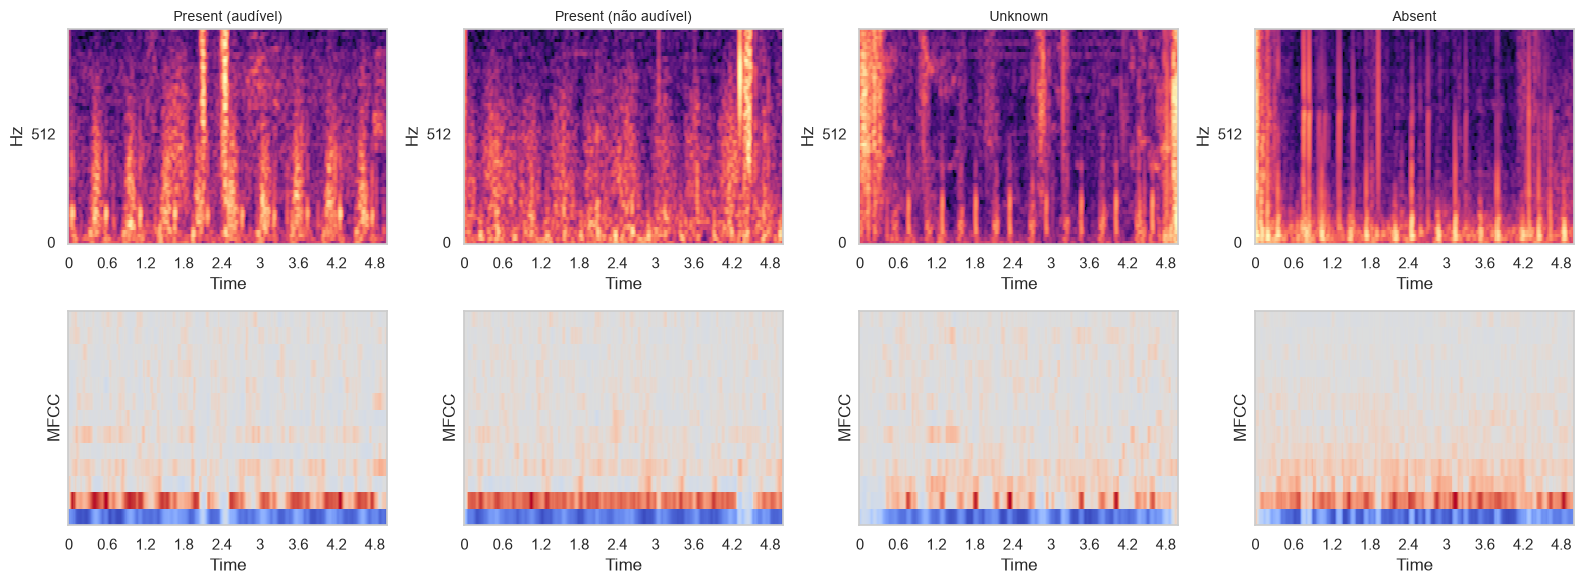

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, (name, rec) in enumerate(examples.items()):
    x = load_audio(rec["wav"])[: 5 * SAMPLE_RATE]
    mel = librosa.feature.melspectrogram(y=x, sr=SAMPLE_RATE, n_fft=512, hop_length=64, n_mels=64, fmax=1000)
    librosa.display.specshow(librosa.power_to_db(mel, ref=np.max), sr=SAMPLE_RATE, hop_length=64,
                             x_axis="time", y_axis="mel", fmax=1000, ax=axes[0, i])
    axes[0, i].set_title(name, fontsize=10)
    mfcc = librosa.feature.mfcc(y=x, sr=SAMPLE_RATE, n_mfcc=13, n_fft=512, hop_length=64, n_mels=64, fmax=1000)
    librosa.display.specshow(mfcc, sr=SAMPLE_RATE, hop_length=64, x_axis="time", ax=axes[1, i])
    axes[1, i].set_ylabel("MFCC")
plt.tight_layout(); plt.show()

**Como ler estas figuras: mel-espectrograma e MFCC**

**Espectrograma (STFT).** O sinal é cortado em janelas curtas que deslizam ao longo do tempo. Para cada janela calcula-se
quanta energia há em cada frequência. O resultado é uma imagem: eixo x = tempo, eixo y = frequência, cor = energia.
Os parâmetros estão em amostras; a 4000 Hz, cada amostra dura 0,25 ms:

| Parâmetro | Valor | Em tempo / frequência |
|---|---|---|
| `n_fft` (tamanho da janela) | 512 amostras | 128 ms; resolução de 4000 / 512 ≈ 7,8 Hz (257 faixas de 0 a 2000 Hz) |
| `hop_length` (passo) | 64 amostras | 16 ms; 5 s de áudio dão 5 × 4000 / 64 + 1 = 313 colunas |

Janela maior = frequências mais nítidas, mas eventos curtos (S1, S2) mais borrados no tempo. 128 ms é um compromisso
(um S1/S2 dura ~100–150 ms).

**Mel-espectrograma** (linha de cima). A escala **mel** imita o ouvido humano: é quase linear até ~1000 Hz e logarítmica acima.
As 257 faixas da STFT são agrupadas em **64 bandas mel** (`n_mels=64`) por filtros triangulares, e a energia é passada para dB.
Cada janela de 5 s vira uma imagem de **64 × 313**, que é a entrada pensada para a **CNN** (bandas vizinhas = frequências vizinhas,
por isso as convoluções fazem sentido).
- Com `fmax=1000`, as 64 bandas ficam **igualmente espaçadas** (15,4 Hz cada): abaixo de 1000 Hz a escala mel do librosa é linear.
  Na prática é um espectrograma linear com metade da resolução, mais pequeno e menos ruidoso.
- O que procurar: no *Absent* vêem-se só "riscos" verticais (S1 e S2); num sopro aparece energia contínua **entre** eles
  (sístole ou diástole).

**MFCC** (linha de baixo, *Mel-Frequency Cepstral Coefficients*). Descrevem com poucos números o **contorno** do espectro em cada
instante. Para cada coluna do mel-espectrograma:

```
64 bandas mel  →  log (dB)  →  DCT (transformada do cosseno)  →  ficar com os 13 primeiros
```

| Coeficiente | Descreve |
|---|---|
| 0 | energia total (volume) |
| 1 | inclinação: mais energia nos graves ou nos agudos? |
| 2–12 | detalhes cada vez mais finos do formato do espectro |

Cada janela de 5 s vira uma **sequência de 313 vetores de 13 números**, a entrada pensada para a **RNN**. Ao contrário do
mel-espectrograma, coeficientes vizinhos não são "vizinhos" físicos, por isso o MFCC não é uma boa imagem para uma CNN.

**Cuidados para os modelos**
- Os coeficientes têm escalas muito diferentes (numa gravação, o coeficiente 0 tem média ~−190 e desvio ~43, os últimos desvio ~5):
  **normalizar cada coeficiente** com média e desvio calculados só no treino.
- Pode-se juntar os **deltas** (variação de cada coeficiente no tempo, `librosa.feature.delta`): 13 → 39 números por instante.
  Ideia a testar (ver `PROGRESSO.md`).

## 7. Divisão treino/validação/teste

A divisão é **70 / 15 / 15 por paciente** (`make_split` em `src/data.py`, com `val_size=0.15`, `test_size=0.15` e `SEED = 42`),
gravada em `data/split.csv`:

| | Pacientes | % | Gravações | % |
|---|---|---|---|---|
| treino | 658 | 69,9 | 2210 | 69,9 |
| validação | 142 | 15,1 | 474 | 15,0 |
| teste | 142 | 15,1 | 479 | 15,1 |

- **Por paciente:** todas as gravações de um paciente ficam no mesmo conjunto. Se não, o modelo podia ver no treino uma gravação
  de um paciente e ser avaliado noutra do mesmo paciente, o que dá resultados otimistas demais.
- **Estratificada pela classe `Murmur`:** os três conjuntos têm as mesmas proporções de *Present* / *Unknown* / *Absent*
  (confirmado abaixo).
- O **teste** só se usa no fim. Escolhas de arquitetura, hiperparâmetros, early stopping e limiares usam a **validação**.

In [15]:
split = load_split().merge(patients[["patient_id", "murmur"]], on="patient_id")
table = pd.crosstab(split["subset"], split["murmur"])[CLASSES].reindex(["train", "val", "test"])
table["total"] = table.sum(axis=1)
display(table)
display((100 * pd.crosstab(split["subset"], split["murmur"], normalize="index")[CLASSES]).round(1).reindex(["train", "val", "test"]))

rec_split = recordings.merge(split[["patient_id", "subset"]], on="patient_id")
print("gravações por subconjunto:", rec_split["subset"].value_counts().to_dict())
assert rec_split.groupby("patient_id")["subset"].nunique().max() == 1, "um paciente está em mais de um subconjunto!"
print("OK: todas as gravações de cada paciente estão no mesmo subconjunto")

murmur,Present,Unknown,Absent,total
subset,,,,
train,125,48,485,658
val,27,10,105,142
test,27,10,105,142


murmur,Present,Unknown,Absent
subset,,,
train,19.0,7.3,73.7
val,19.0,7.0,73.9
test,19.0,7.0,73.9


gravações por subconjunto: {'train': 2210, 'test': 479, 'val': 474}
OK: todas as gravações de cada paciente estão no mesmo subconjunto


## 8. Conclusões

**Classes e métrica**
- 74% *Absent*, 19% *Present*, 7% *Unknown*. Prever sempre *Absent* dá accuracy 0.738 mas WA de apenas 0.387;
  prever sempre *Present* dá WA 0.499. **Qualquer modelo tem de passar de 0.499** para valer a pena.
- O desequilíbrio tem de entrar no treino (pesos de classe na loss ou reamostragem), senão o modelo aprende a dizer *Absent*.

**Rótulo do paciente vs. rótulo da gravação**
- 19% das gravações de pacientes *Present* são de locais onde o sopro **não** foi ouvido. Se cada gravação herdar o rótulo
  do paciente, o modelo é treinado com exemplos *Present* que não têm sopro.
- Opções a testar: (a) rótulo do paciente em todas as gravações; (b) usar `murmur_audible` e tratar as gravações não audíveis
  como *Absent* ou retirá-las do treino.
- Para ter uma previsão por paciente, uma regra natural é: *Present* se pelo menos uma gravação for *Present*.

**O que é *Unknown***
- As gravações *Unknown* têm muito mais trechos não anotados (mediana 76% vs. 39-48% nas outras classes), mais energia em frequências altas
  (ruído) e são mais frequentes em recém-nascidos e bebés. Ou seja, *Unknown* parece significar **gravação de má qualidade**
  e não um tipo de sopro. O modelo pode aprender a reconhecer isso.

**Pré-processamento**
- Durações entre 5.2 e 64.5 s (mediana ~21 s), nenhuma com menos de 5 s. **Janelas de 4-5 s** cabem em todas as gravações e
  dão várias janelas por gravação (mais exemplos de treino).
- A taxa de amostragem é 4000 Hz, por isso o sinal só tem frequências até 2000 Hz. Nos espectrogramas limitámos a **1000 Hz**:
  - **a favor:** em todas as classes, a mediana da energia acima de 1000 Hz é só 2–5% (*Present* audível 1.8%, *Absent* 3.0%,
    *Unknown* 4.9%); os sons cardíacos e os sopros estão nas frequências baixas;
  - **contra:** o *Unknown* tem cerca do dobro da energia acima de 1000 Hz do que o *Present*, e em 10% das gravações essa fração
    passa de 15%. Se for ruído, pode ser justamente a pista que ajuda a reconhecer *Unknown*, e o corte tira-a ao modelo.
  - **Por isso o corte é provisório:** comparar `fmax=1000` com `fmax=2000` nas experiências e escolher pela WA na validação.
- O espetro médio é parecido entre *Present* e *Absent*. A diferença está no padrão ao longo do ciclo cardíaco (sopro
  durante a sístole/diástole), o que motiva uma representação tempo-frequência (CNN) ou uma sequência (RNN).

**Segmentação (.tsv)**
- Útil para alinhar janelas com os batimentos, mas em média ~45% de cada gravação não está anotada, e não sabemos se os dados
  escondidos do bónus terão `.tsv` (**perguntar ao professor**). Por agora, não depender dela na previsão.
- O ficheiro `50782_MV_1.tsv` está corrompido (uma só linha `0 0 28`).

**Divisão dos dados**
- 658 / 142 / 142 pacientes (treino / validação / teste), com as mesmas proporções de classes nos três conjuntos e todas as
  gravações de cada paciente no mesmo conjunto.